# Periodic Gaussian process regression

The Gaussian process half of [Comparison of kernel ridge and Gaussian process regression](https://scikit-learn.org/dev/auto_examples/gaussian_process/plot_compare_gpr_krr.html) fits 40 noisy observations from the first 12 units of a sine wave and predicts across `[0, 30]`. A periodic kernel repeats its learned signal into the future. Multiplying by a fixed RBF kernel makes correlations decay with distance, so the posterior mean tends back toward the prior mean as observations grow more distant. Both models learn a white-noise term.

The [pinned gallery source](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/gaussian_process/plot_compare_gpr_krr.py) is by the scikit-learn developers and licensed under BSD-3-Clause. See the [family license notices](../../LICENSES/gaussian-process-NOTICES) and the companion [KernelRidge walkthrough](../kernel_ridge/plot_compare_gpr_krr.ipynb).

Both implementations use the same seed-zero data and the gallery's initial hyperparameters. Python prepares the data, executes the pinned scikit-learn reference and plots the results. Moxie fits and predicts in native Mojo.

In [1]:
import runpy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_compare_gpr_krr")

reference = runpy.run_path(str(ROOT / "tests/gaussian_process/regression/parity.py"))
Regressor, kernels = reference["GPR"], reference["K"]

## Fit the pinned scikit-learn models

In [2]:
rng = np.random.RandomState(0)
X = np.linspace(0, 30, num=1_000).reshape(-1, 1)
signal = np.sin(X).ravel()
indices = rng.choice(np.arange(400), size=40, replace=False)
X_train = X[indices]
y_train = signal[indices] + 0.5 * rng.randn(len(indices))
nb.share(X=X, X_train=X_train, y_train=y_train)

periodic = 1.0 * kernels.ExpSineSquared(1.0, 5.0, periodicity_bounds=(1e-2, 1e1))
local = periodic * kernels.RBF(15.0, length_scale_bounds="fixed")
expected = {}
for name, covariance in (("periodic", periodic), ("local", local)):
    model = Regressor(kernel=covariance + kernels.WhiteKernel(0.1)).fit(X_train, y_train)
    mean, std = model.predict(X, return_std=True)
    expected[name] = dict(
        mean=mean,
        std=std,
        theta=model.kernel_.theta,
        lml=np.array([model.log_marginal_likelihood_value_]),
        period=np.array([np.exp(model.kernel_.theta[2])]),
    )

## Fit the native Mojo models

The Mojo constructors use typed `Bounds`, including `Bounds.fixed()` for the RBF length scale. The uncertainty overload returns a `PredictionResult` with a mean and an optional standard deviation.

In [3]:
%%mojo periodic_regression
from std.math import exp

from moxie.gaussian_process import GaussianProcessRegressor
from moxie.gaussian_process.kernels import Bounds, ExpSineSquared, RBF, WhiteKernel
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X = load("X")
    var X_train = load("X_train")
    var y_train = load("y_train")
    var periodic = 1.0 * ExpSineSquared(1.0, 5.0, periodicity_bounds=Bounds(1e-2, 1e1))
    var local = periodic * RBF(15.0, Bounds.fixed())
    var models = [periodic + WhiteKernel(0.1), local + WhiteKernel(0.1)]
    var names = ["periodic", "local"]
    for i in range(len(models)):
        var model = GaussianProcessRegressor(models[i].copy())
        _ = model.fit(X_train, y_train)
        var prediction = model.predict(X, return_std=True)
        var name = names[i]
        var theta = model.kernel_.theta()
        save(name + "_mean", prediction.mean)
        save(name + "_std", prediction.std.value())
        save(name + "_theta", theta)
        save_floats(name + "_lml", [model.log_marginal_likelihood_value_])
        save_floats(name + "_period", [exp(theta.item(2))])

## Compare extrapolation and uncertainty

The shaded region spans one posterior standard deviation, as in the gallery. The fixed 15-unit RBF length scale governs how quickly the locally periodic model's prediction falls back toward zero.

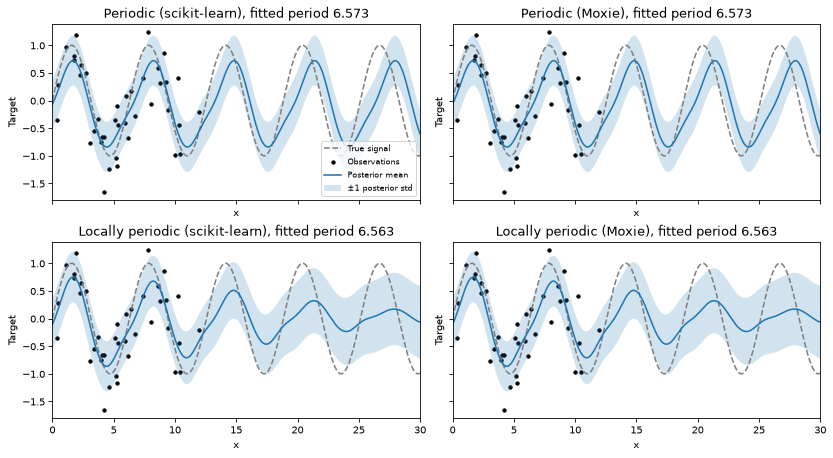

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
periodic: mean,PASS,"(1000,)","(1000,)",1.08e-14,8.05e-12,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
periodic: std,PASS,"(1000,)","(1000,)",6.11e-16,1.37e-15,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
periodic: theta,PASS,"(4,)","(4,)",1.85e-14,6.3e-14,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
periodic: lml,PASS,"(1,)","(1,)",2.13e-14,7.36e-16,"rtol=1e-11, atol=1e-11",,"The likelihood is stationary at the optimum, so small theta differences change it only to second order."
periodic: period,PASS,"(1,)","(1,)",5.57e-12,8.47e-13,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
local: mean,PASS,"(1000,)","(1000,)",3e-15,4.27e-13,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
local: std,PASS,"(1000,)","(1000,)",1.44e-15,2.21e-15,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
local: theta,PASS,"(4,)","(4,)",7.77e-15,1.47e-14,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.
local: lml,PASS,"(1,)","(1,)",1.07e-14,3.61e-16,"rtol=1e-11, atol=1e-11",,"The likelihood is stationary at the optimum, so small theta differences change it only to second order."
local: period,PASS,"(1,)","(1,)",5.56e-12,8.47e-13,"rtol=1e-07, atol=1e-08",,Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute tolerance covers near-zero means and log parameters.


In [4]:
actual = nb.results["periodic_regression"]
metrics = ("mean", "std", "theta", "lml", "period")
fig, axes = plt.subplots(2, 2, figsize=(11, 6), dpi=75, sharex=True, sharey=True,
                         layout="constrained")
for row, (name, title) in enumerate((("periodic", "Periodic"), ("local", "Locally periodic"))):
    native = {metric: actual[f"{name}_{metric}"] for metric in metrics}
    for ax, (label, result) in zip(axes[row], (("scikit-learn", expected[name]), ("Moxie", native))):
        ax.plot(X[:, 0], signal, linestyle="--", color="0.5", label="True signal")
        ax.scatter(X_train[:, 0], y_train, s=10, color="black", label="Observations")
        ax.plot(X[:, 0], result["mean"], label="Posterior mean")
        ax.fill_between(X[:, 0], result["mean"] - result["std"],
                        result["mean"] + result["std"], alpha=0.2, label="±1 posterior std")
        ax.set_title(f"{title} ({label}), fitted period {result['period'][0]:.3f}")
        ax.set(xlabel="x", ylabel="Target", xlim=(0, 30))
axes[0, 0].legend(loc="lower right", fontsize=8)
plt.show()

for name in expected:
    for metric in metrics:
        rtol, atol = (1e-11, 1e-11) if metric == "lml" else (1e-7, 1e-8)
        reason = ("The likelihood is stationary at the optimum, so small theta differences "
                  "change it only to second order." if metric == "lml" else
                  "Cholesky and distance rounding can shift the L-BFGS-B endpoint. Absolute "
                  "tolerance covers near-zero means and log parameters.")
        nb.compare(f"{name}: {metric}", expected[name][metric], actual[f"{name}_{metric}"],
                   rtol=rtol, atol=atol, reason=reason)
nb.report()
nb.assert_parity()